In [112]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [113]:

numTeste = [12, 21, 30, 32]
numTreino = [1, 2, 4, 9, 10, 11, 13, 22, 23, 25]

testes = [cv2.imread(f"treino/lego{n}.jpg") for n in numTeste]
treino = [cv2.imread(f"treino/lego0{n}.jpg" if n < 10 else f"treino/lego{n}.jpg") for n in numTreino]


Em tons de cinzento, o fundo azul e algumas peças (vermelha, verde, laranja...) ficam com brilho parecido, e nenhum limiar, fixo ou Otsu, as consegue separar. O problema não é o valor do limiar, é que o brilho não distingue fundo de peças. A solução é segmentar pela cor. Ou seja, em ves de ler a imagem em tons de cinzento, esta sera lida com as cores originais e usa-se o fundo azul como referência. 

Porque funciona: no fundo azul, B é bastante maior que R e G, mesmo nas zonas de sombra (fica mais escuro, mas continua azul). Nas peças isso não acontece: vermelha e laranja têm R alto, a verde tem G alto, a amarela tem R e G altos, e a bege/branca/cinzenta tem os três canais parecidos, logo B não ganha por margem. Os valores 40 e 20 são o ponto de partida, e deves ajustá-los vendo as máscaras.

O 255 - fundo funciona porque fundo é um array uint8 só com 0 e 255: onde era 255 (fundo) passa a 0, e onde era 0 (peça) passa a 255. Assim, o treino_bin tem todas as imagens em binario, ou seja, peças a branco e fundo a preto.

Medimos a instensidade em cada canal BGR em diferentes sítios na imagem (canto esquerdo, centro e canto direito), para ver o intervalo em que cada canal variava, e desta forma, definir de uma maneira mais rigorosa onde é o fundo, eliminando possíveis erros, como haver valores fora dos intervalos definidos e partes do fundo (como as bordas) serem detetadas como peças.  

Canto esquerdo:  [234 164  73]
Centro:  [198 124  66]
Canto direito [221 149  71]


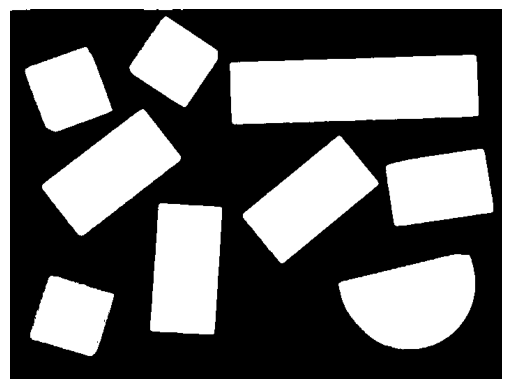

In [114]:
#Binarização

#treino_bin = [cv2.threshold(img, 140, 255, cv2.THRESH_BINARY)[1] for img in treino]

def segmentar(img):
    #fundo = cv2.inRange(img, (150, 90, 0), (255, 200, 110))   # (B, G, R) min e max
    fundo = cv2.inRange(img, (95, 75, 0), (255, 200, 110))   # mudei por causa das sombras das peças
    return 255 - fundo                                        # peças = branco, fundo = preto


#estes valores estão em bgr, pq a imagem foi lida assim
print("Canto esquerdo: ", treino[0][10, 10])      # canto
print("Centro: ", treino[0][260, 350])    # centro (zona de fundo)
print("Canto direito", treino[0][500, 20])     # outro canto
treino_bin = [segmentar(img) for img in treino]


plt.imshow(treino_bin[0],cmap="gray")
plt.axis("off")
plt.show()


#hist = cv2.calcHist([treino[2]], [0], None, [256], [0, 256])


Os Operadores Morfológicos limpam a imagem binaria antes da extração dos contornos. Faz-se abertura(erosão -> dilatação) para remover as partes brancas e mais pequenas que nao fazem parte das peças. Faz-se o fecho (dilatação -> erosão) para fechar pequenos buracos, como os reflexos nos pinos do Lego. A abertura vem primeiro para remover o ruído antes de fechar, senão o fecho consolidava os pontos de ruído junto às peças e podia voltar a ligar peças proximas. 

A cross ficava com vários pontinhos brancos onde não existiam peças. O rect era bem aproveitado se todas as peças estivessem direitas mas como não estão os cantos comecaçam a desaparecer e a ficar redondos. Então a ellipse foi a melhor opção, uma vez que não deformou as peças, nem acrescentou ruído extra. 

Erodimos 5 vezes porque testámos e pq...(pesquisar potencial motivo). 

(np.float64(-0.5), np.float64(705.5), np.float64(524.5), np.float64(-0.5))

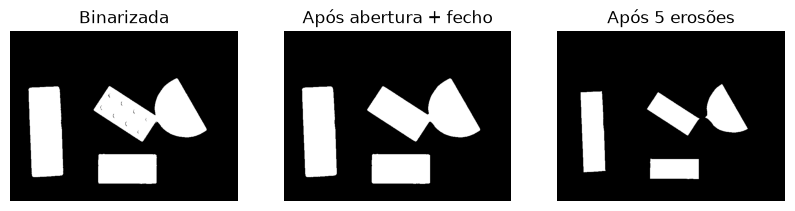

In [115]:
#Operadores Morfológicos

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7,7)) # elemento estruturante

#
# O fecho é melhor 

# A função limpar aplica abertura seguida de fecho a uma imagem binária
# Problema: não separam peças muito próximas
def limpar(bin_):
    abertura = cv2.morphologyEx(bin_, cv2.MORPH_OPEN, kernel)    # abertura
    fecho = cv2.morphologyEx(abertura, cv2.MORPH_CLOSE, kernel)   # fecho
    return fecho

# A função separar aplica erosão a uma imagem limpa para separar as peças
# o 5 foi escolhido depois de testar com vários valores (célula a seguir)
def separar(limpa, it=5):
    return cv2.erode(limpa, kernel, iterations=it) 

treino_limpo = [limpar(b) for b in treino_bin]
treino_sep   = [separar(l) for l in treino_limpo]

fig, ax = plt.subplots(1, 3, figsize=(10, 4))

ax[0].imshow(treino_bin[6], cmap="gray")
ax[0].set_title("Binarizada")
ax[0].axis("off")

ax[1].imshow(treino_limpo[6], cmap="gray")
ax[1].set_title("Após abertura + fecho")
ax[1].axis("off")

ax[2].imshow(treino_sep[6], cmap="gray")
ax[2].set_title("Após 5 erosões")
ax[2].axis("off")

In [116]:
# # TESTE DE EROSÃO: para concluir quantas iterações de erosão são necessárias para separar peças em contacto

# idx = [0, 3, 4, 6]          # imagens com contactos entre peças e objetos de ruído, e uma imagem com várias peças
# its = [4, 5,6]

# fig, ax = plt.subplots(len(idx), 2 + len(its), figsize=(14, 3 * len(idx)))

# for r, i in enumerate(idx):
#     ax[r, 0].imshow(treino_bin[i], cmap="gray")   
#     ax[r, 0].set_title("Binarizada")
#     ax[r, 1].imshow(treino_limpo[i], cmap="gray")
#     ax[r, 1].set_title("Abertura+fecho")

#     for c, it in enumerate(its):
#         ax[r, 2 + c].imshow(separar(treino_limpo[i], it), cmap="gray") 
#         ax[r, 2 + c].set_title(f"Erosão it={it}")

# for a in ax.ravel(): a.axis("off")
# plt.tight_layout()
# plt.show()

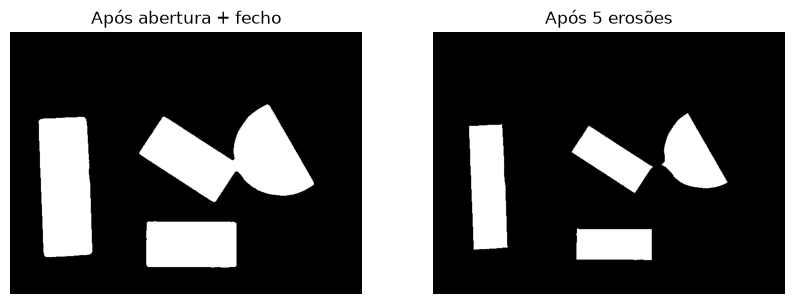

Imagem limpa:  3
Imagem com peças separadas:  4


In [117]:
# Etiquetação

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(treino_limpo[6], cmap="gray")
ax[0].set_title("Após abertura + fecho")
ax[0].axis("off")

ax[1].imshow(treino_sep[6], cmap="gray")
ax[1].set_title("Após 5 erosões")
ax[1].axis("off")
plt.show()

n_limpo, etiquetas_limpo = cv2.connectedComponents(treino_limpo[6]) # número de objetos, etiquetas
n_sep, etiquetas_sep = cv2.connectedComponents(treino_sep[6]) # número de objetos, etiquetas
print("Imagem limpa: ", n_limpo - 1) # 0 é o fundo, daí subtraí-se 1
print("Imagem com peças separadas: ", n_sep - 1) 

A imagem original tem 4 peças mas duas juntas, e usando a imagem limpa apenas se detetam 3 peças
Na imagem com peças separadas já dá o resultado correto

4


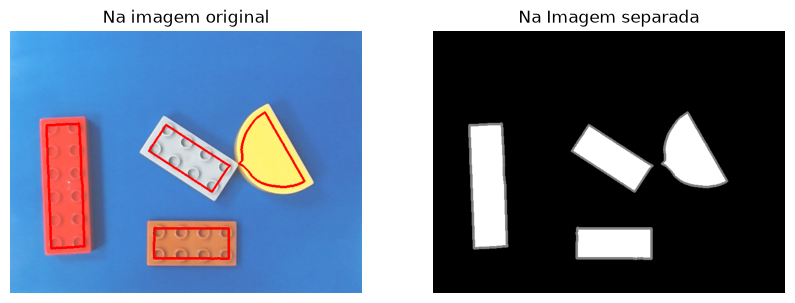

In [118]:
# findContours -> devolve uma lista de pontos da fronteira, e cada contorno corresponde a um objeto.
# drawContours desenha esses contornos, ou preenche-os se thickness=-1, o que dá uma máscara por peça.
# Os contornos servem depois para o próximo passo

contornos, _ = cv2.findContours(treino_sep[6], cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE) 
# RETR_EXTERNAL apanha só os contornos exteriores
# CHAIN_APPROX_SIMPLE guarda só os pontos finais de cada linha (poupa memória)

print(len(contornos)) # número de objetos encontrados

img_org = treino[6].copy()
cv2.drawContours(img_org, contornos, -1, (0, 0, 255), 3)

img_sep = treino_sep[6].copy()
cv2.drawContours(img_sep, contornos, -1, 128, 3) # contornos a cinzento

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(img_org[:, :, ::-1])
ax[0].set_title("Na imagem original")
ax[0].axis("off")

ax[1].imshow(img_sep, cmap="gray")
ax[1].set_title("Na Imagem separada")
ax[1].axis("off")
plt.show()

Na imagem original os contornos estão mais pequenos porque as erosões diminuiram os tamanhos das peças.

In [119]:
# # Extração de Características

# minAreas = [cv2.minAreaRect(c) for c in contornos]

# img = treino_sep[6].copy()
# for k, r in enumerate(minAreas):
#     caixa = cv2.boxPoints(r).astype(np.int32)
#     cv2.drawContours(img, [caixa], -1, 128, 3)          # 128 = cinzento
#     plt.text(r[0][0], r[0][1], str(k), color="red", fontsize=14)

# plt.imshow(img, cmap="gray")
# plt.axis("off")
# plt.show()

In [120]:
# contourArea = [cv2.contourArea(c) for c in contornos]

# plt.imshow(treino_sep[6], cmap="gray")
# for k, (r, area) in enumerate(zip(minAreas, contourArea)):
#     (cx, cy), (w, h), ang = r
#     plt.text(cx, cy, "%d\n%.0f px²\next %.2f" % (k, area, area / (w * h)),
#              color="red", fontsize=10, ha="center", va="center")
# plt.axis("off")
# plt.show()
# # número do objeto
# # área do contorno em pixeis
# # extensão = área / área do retângulo rodado

minAreaRect: Melhor escolha. As razões teóricas são 1, 2, 3 e 4, e não dependem da rotação da peça.
contourArea: Boa, como confirmação. Proporcional ao nº de pinos (4, 8, 12, 16), e como a câmara é paralela à mesa e está fixa, a escala é constante
contourArea + minAreaRect: Boa para filtrar ruído. Peças retangulares dão valores próximos de 1, e as outras peças de Lego presentes na imagem ficam abaixo.

In [121]:
margem = 5 * 3 * 2
# 5 × 3 = 15 px são o que se perde num lado
# A largura tem dois lados (esquerdo e direito), por isso perde 2 × 15 = 30 px
# O comprimento também tem dois lados (cima e baixo), por isso também perde 30 px
# Por isso a margem é somada à largura e ao comprimento (*AQUI)

# função que recebe um contorno e devolve as suas medidas num dicionário
def medir(contorno):
    
    (cx, cy), (w, h), _ = cv2.minAreaRect(contorno)
    # minAreaRect calcula o menor retângulo, possivelmente rodado, que contém o contorno
    # (cx, cy): o centro do retângulo
    # (w, h): a largura e a altura desse retângulo

    area = cv2.contourArea(contorno) 
    # Área da região dentro do contorno, em píxeis. É a área da peça real (depois da erosão), e não a do retângulo.

    ret = area / (w * h) # retangularidade (sem compensação, é só uma razão de áreas)
    # Retangularidade: área da peça a dividir pela área do retângulo mínimo w * h 
    # Se a peça for um retângulo perfeito, os dois valores coincidem e o resultado é 1
    # Se for outra forma, a peça preenche só parte do retângulo e o valor desce (o semicírculo deu cerca de 0,79)
    # Está antes da compensação de propósito: a area do contorno é a erosionada, por isso w * h também tem de ser 
    # Se somasses a margem primeiro, estarias a comparar uma área pequena com um retângulo já “reposto”, 
    # e a razão ficaria errada.

    w += margem # (*AQUI)
    h += margem # (*AQUI)

    maior, menor = max(w, h), min(w, h)
    # minAreaRect pode devolver w como o lado curto ou o comprido, conforme a rotação da peça
    # Com max e min, maior é sempre o lado comprido e menor o lado curto 
    # Assim a razão maior / menor é sempre ≥ 1 e não depende da orientação.

    return {"centro": (cx, cy), "maior": maior, "menor": menor,
            "razao": maior / menor, "area": area, "retangularidade": ret}

# Calibração numa só imagem
i = 6
conts, _ = cv2.findContours(treino_sep[i], cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE) # TIRAR ISTO 
# JÁ ESTÁ FEITO LÁ EM CIMA MAS VAI TER QUE SER ALTERADO PARA SER GLOBAL

for c in conts:
    m = medir(c)
    print(f"img {i} | razão {m['razao']:.2f} | área {m['area']:.0f} | ret {m['retangularidade']:.2f}")
    # NECESSÁRIO PERCORRER TODAS DE TREINO PARA ANALISAR MELHOR OS VALORES E TIRAR CONCLUSÕES

img 6 | razão 1.98 | área 9006 | ret 0.98
img 6 | razão 1.94 | área 9416 | ret 0.96
img 6 | razão 2.83 | área 16394 | ret 0.97
img 6 | razão 1.49 | área 11012 | ret 0.71


{'2x2': 3, '2x4': 3, '2x6': 0, '2x8': 1}


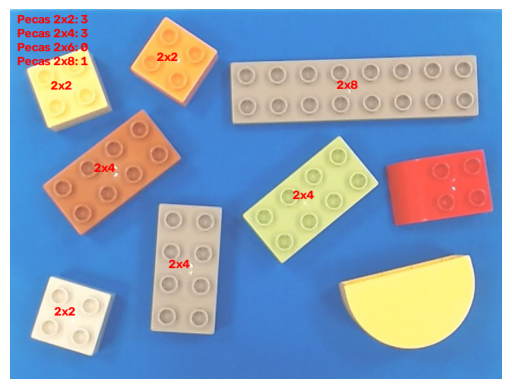

In [122]:
# Classificação

def classificar(m):
    # rejeitar o que não é retangular (semicírculo, outras peças, ruído)
    if m["retangularidade"] < 0.85:
        return None
    r = m["razao"]
    # classificar pela razão, com zonas de rejeição entre as classes
    if 0.85 <= r <= 1.25:
        return "2x2"
    elif 1.75 <= r <= 2.25:
        return "2x4"
    elif 2.6 <= r <= 3.3:
        return "2x6"
    elif 3.5 <= r <= 4.3:
        return "2x8"
    return None   # razão fora das classes (ex.: peça vermelha curva, 1.54)

# Escreve na imagem as peças identificadas
def contar(img_bin, img_cor):
    contagem = {"2x2": 0, "2x4": 0, "2x6": 0, "2x8": 0}
    saida = img_cor.copy()
    conts, _ = cv2.findContours(img_bin, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    for c in conts:
        m = medir(c)
        tipo = classificar(m)
        if tipo is None:
            continue                      # peça rejeitada: não se escreve nada
        contagem[tipo] += 1
        cx, cy = m["centro"]
        cv2.putText(saida, tipo, (int(cx) - 25, int(cy)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)   # vermelho (BGR)

    # resumo no canto superior esquerdo
    for k, tipo in enumerate(["2x2", "2x4", "2x6", "2x8"]):
        cv2.putText(saida, f"Pecas {tipo}: {contagem[tipo]}", (10, 20 + 20 * k),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)
    return contagem, saida


i = 0
contagem, saida = contar(treino_sep[i], treino[i])
print(contagem)
plt.imshow(saida[:, :, ::-1])
plt.axis("off")
plt.show()

a peça vermelha é 2x4 no entanto como está vista de um angulo onde se vê a altura, ao calcular a área ficaria fora do intervalo esperado ou de qualquer outro intervalo sendo o mais correto porque se não deteta que é 2x4 mais vale ser rejeitada do que mal classificada.